# Predicting Monthly Employment Earnings Among Young Rwandans

**Machine Learning Assignment, Task 1: Regression Models**
African Leadership University (ALU), BSc Software Engineering

## 1. Introduction

### Mission
> To create technology-driven financial and employment solutions that enable African youth to access income opportunities, build economic resilience, and transition into sustainable livelihoods.

In short: *to create technology solutions that support businesses and young people.*

### Problem statement
Young people entering the labour market often have limited information about the income they can expect from employment. Earnings vary with age, gender, education, occupation, industry, work experience, working hours, employment conditions and whether the employer is in the formal or informal sector.

This notebook builds a machine learning model that **predicts the estimated monthly cash earnings (in Rwandan francs, RWF) of a young employed person in Rwanda** from their demographic, educational and employment characteristics.

### Use case and intended users
The model turns labour-market survey data into an income estimate that could support:
- young job seekers making career and employment decisions;
- employment-support organisations advising young people;
- workforce-development organisations analysing income patterns;
- organisations building technology-driven employment and financial solutions.

The model is **not** a guarantee of anyone's future salary. It describes what similar young employees in the survey reported earning.

### Prediction objective
The dependent variable is `cash`, defined by the National Institute of Statistics of Rwanda (NISR) as *monthly income in cash for employees*, measured in RWF. It is continuous and numerical, so this is a **regression** problem:

$$Y = f(X_1, X_2, \dots, X_n)$$

where $Y$ is the predicted monthly cash earnings in RWF and $X_1 \dots X_n$ describe the person and their job.

### Connection to the mission
This project addresses the *income opportunity* part of the mission. Giving a young person a data-based estimate of what people with a similar profile earn supports employment planning and economic decision-making. The same trained pipeline is saved so that a later API and mobile application can serve these estimates to young people directly.

### Dataset source and attribution
| Item | Detail |
|---|---|
| Dataset | Rwanda Labour Force Survey 2025 (LFS 2025) |
| Data producer | National Institute of Statistics of Rwanda (NISR). Official catalogue: https://microdata.statistics.gov.rw/index.php/catalog/125 |
| File used | `RW_LFS2025_3.csv`, the microdata file downloaded directly from the NISR website |

The file contains 100,852 individual-level observations and 207 original survey variables, collected through Computer-Assisted Personal Interviewing (CAPI) in February, May, August and November 2025. It covers demographic, education, employment, occupational and labour-market information.

A processed copy of the same survey, published on Hugging Face by Electric Sheep Africa, was examined first. It has the same number of rows, but its content differs from the NISR file for a large share of rows on the columns compared, so this notebook uses the official NISR file only, and every result below comes from it.

This is real survey data, not a synthetic or tutorial dataset. The numeric income target exists for **employees only**; this is not a freelancer-income dataset.

## 2. Import libraries

The cell below installs any library that is missing (Google Colab already has all of them) and then imports what the notebook needs. A single `RANDOM_STATE` is used everywhere so results are reproducible.

In [ ]:
import sys, subprocess, importlib

def ensure_installed(pip_name, module_name=None):
    """Install a package only if it cannot be imported (useful on a fresh Colab runtime)."""
    try:
        importlib.import_module(module_name or pip_name)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name])

for pip_name, module_name in [("pandas", None), ("numpy", None), ("matplotlib", None),
                              ("seaborn", None), ("scikit-learn", "sklearn"), ("joblib", None)]:
    ensure_installed(pip_name, module_name)

In [ ]:
import copy
import json
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

RANDOM_STATE = 42                      # one seed used for every random operation
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
print("scikit-learn version:", sklearn.__version__)

scikit-learn version: 1.6.1


## 3. Load the dataset

The notebook looks for `RW_LFS2025.csv` in the current folder, then in `/content` (the Colab upload area), then in Google Drive. If it is not found and the notebook is running in Colab, it opens an upload dialog. To run on Colab, either upload the CSV in the left-hand file panel or use the dialog that appears.

In [ ]:
CSV_NAME = "RW_LFS2025.csv"
candidate_paths = [Path(CSV_NAME), Path("/content") / CSV_NAME, Path("/content/drive/MyDrive") / CSV_NAME]
csv_path = next((p for p in candidate_paths if p.exists()), None)

if csv_path is None:
    try:
        from google.colab import files          # only available inside Google Colab
        print(f"Please upload {CSV_NAME}")
        files.upload()
        csv_path = Path(CSV_NAME)
    except ImportError:
        raise FileNotFoundError(f"{CSV_NAME} not found. Place it next to this notebook.")

df_raw = pd.read_csv(csv_path, low_memory=False)
print("Loaded from:", csv_path)
print("Dataset shape (rows, columns):", df_raw.shape)

Loaded from: RW_LFS2025.csv
Dataset shape (rows, columns): (100852, 207)


### Validate and tidy the file
Three things are done once, here, so that every later step sees clean data.

1. **Check the file.** The columns this project needs must exist, otherwise the notebook stops. If the row or column count differs from the complete NISR file (100,852 rows and 207 columns) a warning is printed, because the figures quoted in the written commentary of this notebook were calculated on the complete file and will not match a partial copy.
2. **Tidy the text.** The NISR file uses upper-case column names, and some text labels carry stray leading spaces (for example `" Elementary_occupations"`). Column names are converted to lower case and text values are stripped of surrounding spaces, so the same job is never split into two categories.
3. **Apply a plausibility limit to `cash`.** A monthly cash income above **10,000,000 RWF** is treated as a probable data-entry error and set to *missing* (it is then excluded by the "valid `cash` value" condition, like any other missing income; it is not replaced with zero). The limit is a rule, not a hand-picked row, and it is about 250 times the median income. In the complete NISR file it affects two records, 34,000,000 and 41,800,000 RWF; the next highest value is 5,000,000 RWF, so every other high income is kept. Both values are in the open-ended survey band "1,000,000 RWF and above", so the band cannot confirm them, and each looks like an extra digit. This cannot be proven, but a single value of this size would add more than 100 billion to the MSE of any model, which is more than the whole error level of the models, and would decide every comparison. In the CSV these values are stored in scientific notation (for example `3.40e+07`), so a text search for `34000000` will not find them. If a copy of the file has no such values, nothing is changed.

In [ ]:
EXPECTED_SHAPE = (100852, 207)
REQUIRED_COLUMNS = ["a04", "a01", "b02a", "indd01", "main_sect", "usual_h", "d24", "d24b",
                    "prod_unit", "d08", "d05", "cash"]

df_raw.columns = df_raw.columns.str.lower()                  # A04 -> a04, Prod_unit -> prod_unit, ...
missing_columns = [c for c in REQUIRED_COLUMNS if c not in df_raw.columns]
if missing_columns:
    raise ValueError(f"Required columns not found: {missing_columns}. Please check the file.")
if df_raw.shape != EXPECTED_SHAPE:
    print(f"WARNING: this file has shape {df_raw.shape}, not the complete NISR file {EXPECTED_SHAPE}. "
          "The notebook will still run, but the numbers quoted in the text refer to the complete file.")

text_columns = df_raw.select_dtypes(exclude="number").columns
for column in text_columns:
    df_raw[column] = df_raw[column].str.strip()              # remove stray leading/trailing spaces

# Plausibility limit on monthly cash income (see the explanation above)
MAX_PLAUSIBLE_MONTHLY_CASH = 10_000_000
too_large = df_raw["cash"] > MAX_PLAUSIBLE_MONTHLY_CASH
print("Monthly cash values above 10,000,000 RWF set to missing:", int(too_large.sum()))
if too_large.any():
    print(df_raw.loc[too_large, ["cash", "a04", "d05", "indd01", "intcash"]].to_string())
df_raw.loc[too_large, "cash"] = np.nan

print("File shape:", df_raw.shape)
print("Occupation labels after cleaning:", sorted(df_raw["indd01"].dropna().unique()))

Monthly cash values above 10,000,000 RWF set to missing: 2
               cash  a04       d05                     indd01                  intcash
13287 41,800,000.00   48  Employee  Service_and_sales_workers  1,000,000 RWF and above
76349 34,000,000.00   29  Employee                   Managers  1,000,000 RWF and above
File shape: (100852, 207)
Occupation labels after cleaning: ['Clerical_support_workers', 'Craft_and_related_trades_workers', 'Elementary_occupations', 'Managers', 'Plant_and_machine_operators_and_assemblers', 'Professionals', 'Service_and_sales_workers', 'Skilled_agricultural,_forestry_and_fishery workers', 'Technicians_and_associate_professionals']


In [ ]:
# The file has 219 columns, so the preview shows the columns relevant to this project only.
KEY_COLUMNS = ["a04", "a01", "b02a", "indd01", "main_sect", "usual_h", "d24", "d24b",
               "prod_unit", "d08", "d05", "cash"]
df_raw[KEY_COLUMNS].head()

,a04,a01,b02a,indd01,main_sect,usual_h,d24,d24b,prod_unit,d08,d05,cash
0,46,Male,Primary education,Service_and_sales_workers,Services,66.00,26.00,12.00,Informal Sector,NaN,Employee,"90,000.00"
1,45,Female,Primary education,Service_and_sales_workers,Services,77.00,3.00,12.00,Informal Sector,NaN,Own account worker,NaN
2,20,Female,Upper secondary education,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,19,Male,Upper secondary education,Service_and_sales_workers,Services,77.00,1.00,7.00,Informal Sector,NaN,Contributing family worker,NaN
4,16,Female,Lower secondary education,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
# All 219 column names, printed compactly (12 per line)
names = df_raw.columns.tolist()
for i in range(0, len(names), 12):
    print(", ".join(names[i:i + 12]))

psu_no, qh_no, hhid, province, code_ur, code_dis, lfs_strata, lfs_year, weight2, a01, a02, a03m
a03y, a04, a05, a06, a07, a08, a09, a10, a11, a12, a13, a14a
a14b, a15, a16y, a17a, a17b, a19, a20, b01, b02a, b02b, b07, b08
b09, b10, b13, b13b, b14, b15, c01, c02, c02a, c03, c05, c06
c07, c08, c09, c09a, c10, c10a, c11a, c11b, c12a, c12b, c13a, c13b
c14, c15, c16, c17, c18, c19, c19a, c20, c20a, c21, c22, c23
c24, c25, c26, d03a, d04, d05, d05a, d05a1, d06, d07, d08, d08a
d09a, d10, d10a, d10b, d10c, d10d, d10_e, d12_1, d12_1a, d13_1, d14_1, d14_1a
d17_1, d18a, d18a_other, d20, d21, d21a, d23, d23a, d23b, d24, d24b, d25a
d25b, ds07, ds08, ds09, ds09aa, ds09aaa, ds09_a, ds09_b, ds09_c, ds09_d, ds10a, f01a
f01b, f02, f05, g01, g01a, g02, g02a, g03, g03a, g04, g04a, g05
g05a, g06, g06a, g07, g07a, h01, h02, h03, h05, h06, h09, h10
indd01, indd03, en01, en01_others, status1, indb05, wap16, employed16, ur1, lfpr, sub, tru
plf, youth, young, luu, disable, discourage, willing, migrant, neetyout

In [ ]:
# Data types: a summary for the whole file and the exact types of the columns we care about
print(df_raw.dtypes.astype(str).value_counts().to_string())
print()
print(df_raw[KEY_COLUMNS].dtypes.astype(str).to_string())

object     140
float64     60
int64        7

a04            int64
a01           object
b02a          object
indd01        object
main_sect     object
usual_h      float64
d24          float64
d24b         float64
prod_unit     object
d08           object
d05           object
cash         float64


In [ ]:
# Basic descriptive statistics for the numerical key columns
df_raw[["a04", "usual_h", "d24", "d24b", "cash"]].describe()

,a04,usual_h,d24,d24b,cash
count,"100,852.00","34,712.00","34,712.00","34,712.00","22,393.00"
mean,25.33,35.11,12.67,9.69,"77,740.39"
std,19.59,18.71,11.77,3.51,"152,281.07"
min,0.00,1.00,0.00,1.00,"1,000.00"
25%,9.00,20.00,3.00,8.00,"26,000.00"
50%,20.00,36.00,10.00,12.00,"39,000.00"
75%,38.00,48.00,20.00,12.00,"78,000.00"
max,95.00,120.00,75.00,12.00,"5,000,000.00"


**What this shows.** The file has 100,852 rows and 207 columns (60 decimal, 7 integer and 140 text columns), exactly the size of the official NISR microdata. The preview shows how the survey is structured: the first person is an employee with a cash income, the second is an own-account worker (no `cash` value), and the third has no employment information at all. Across the whole survey `cash` is recorded only for working people (about 22,000 of the 100,852), so income values need careful checking before any modelling.

**Decisions.** The tidy step (next cell) stops the notebook if required columns are missing and prints a warning if the file is not the complete NISR file. Column names are converted to lower case, text labels are stripped of stray spaces so that the same occupation or province is never split into two categories, and a plausibility limit is applied to `cash`; the reasons are given in the explanation above that cell.

**Note on reproducibility.** The numbers quoted in the explanations come from the run saved in this notebook. Re-running with a different scikit-learn version may change the model scores slightly; the data counts will not change.

## 4. Initial data inspection

Before selecting anything, check missing values, duplicates, data types, the employment categories and the age distribution. The pattern of missing values is especially important here because the survey only asks income questions to some respondents. The file has no person identifier column, so duplicates can only be judged from identical rows.

In [ ]:
# Missing values in the key columns across the entire survey
missing_table = pd.DataFrame({
    "missing": df_raw[KEY_COLUMNS].isna().sum(),
    "missing_pct": (df_raw[KEY_COLUMNS].isna().mean() * 100).round(1),
    "unique_values": df_raw[KEY_COLUMNS].nunique(),
})
missing_table

,missing,missing_pct,unique_values
a04,0,0.00,96
a01,0,0.00,2
b02a,41350,41.00,5
indd01,66140,65.60,9
main_sect,66140,65.60,3
usual_h,66140,65.60,113
d24,66140,65.60,73
d24b,66140,65.60,12
prod_unit,66594,66.00,3
d08,84825,84.10,7


In [ ]:
# Duplicate observations. This file has no person-level identifier, so only identical rows can be detected.
print("Fully duplicated rows in the whole survey:", df_raw.duplicated().sum())
young_employees = df_raw[df_raw["a04"].between(18, 35) & (df_raw["d05"] == "Employee") & df_raw["cash"].notna()]
print("Fully duplicated rows among the young employees with a cash value:", young_employees.duplicated().sum())

Fully duplicated rows in the whole survey: 247
Fully duplicated rows among the young employees with a cash value: 0


In [ ]:
# Employment categories (d05) and where the target `cash` is actually recorded
d05_filled = df_raw["d05"].fillna("Not employed / not asked")
employment_summary = pd.DataFrame({
    "people": d05_filled.value_counts(),
    "with_cash_value": df_raw["cash"].notna().groupby(d05_filled).sum(),
})
employment_summary

,people,with_cash_value
d05,,
Contributing family worker,1584,85
Employee,22071,22008
Employer,722,0
Member of cooperative,19,0
Not employed / not asked,66671,300
Own account worker,9785,0


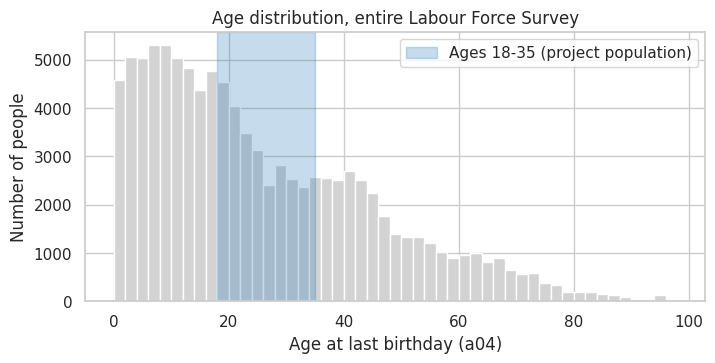

In [ ]:
# Age distribution of the whole survey, with the 18-35 target range highlighted
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(df_raw["a04"], bins=range(0, 100, 2), color="lightgrey", edgecolor="white")
ax.axvspan(18, 35, color="tab:blue", alpha=0.25, label="Ages 18-35 (project population)")
ax.set_xlabel("Age at last birthday (a04)")
ax.set_ylabel("Number of people")
ax.set_title("Age distribution, entire Labour Force Survey")
ax.legend()
plt.show()

In [ ]:
# Number of observations remaining after each filtering stage (counts are computed, not typed in)
stage_all = df_raw
stage_age = stage_all[stage_all["a04"].between(18, 35)]
stage_employee = stage_age[stage_age["d05"] == "Employee"]
stage_cash = stage_employee[stage_employee["cash"].notna()]

filter_counts = pd.DataFrame({
    "Filtering stage": ["Entire dataset", "Aged 18-35", "Aged 18-35 and Employee", "... with a numerical cash value"],
    "Observations": [len(stage_all), len(stage_age), len(stage_employee), len(stage_cash)],
})
filter_counts

,Filtering stage,Observations
0,Entire dataset,100852
1,Aged 18-35,27867
2,Aged 18-35 and Employee,11264
3,... with a numerical cash value,11232


**Findings.**

## 5. Target investigation: `cash`

`cash` is monthly cash income for employees, in RWF. Before using it, check how many values exist, what they look like, and whether the extreme values are plausible. The columns `d12_1a` and `d14_1a` (empty in the downloaded file) and `intcash` (income *bands*, not exact amounts) are deliberately **not** used as the target.

In [ ]:
# Confirm the two tempting alternatives are unusable
print("d12_1a non-missing values:", df_raw["d12_1a"].notna().sum())
print("d14_1a non-missing values:", df_raw["d14_1a"].notna().sum())
print("intcash example values   :", df_raw["intcash"].dropna().unique()[:4].tolist())

d12_1a non-missing values: 0
d14_1a non-missing values: 0
intcash example values   : ['80,000 - 99,999 FRW', '50,000-79,999 RWF', '30,000-49,999 RWF', '100,000-199,999RWF']


In [ ]:
# Summary statistics of the target for young employees (before dropping the few missing cash values)
cash_young_emp = stage_employee["cash"]
target_stats = pd.Series({
    "Valid observations": cash_young_emp.notna().sum(),
    "Missing observations": cash_young_emp.isna().sum(),
    "Minimum (RWF)": cash_young_emp.min(),
    "Maximum (RWF)": cash_young_emp.max(),
    "Mean (RWF)": cash_young_emp.mean(),
    "Median (RWF)": cash_young_emp.median(),
    "Standard deviation (RWF)": cash_young_emp.std(),
    "Zero values": (cash_young_emp == 0).sum(),
    "Skewness": cash_young_emp.skew(),
})
target_stats.to_frame("cash")

,cash
Valid observations,"11,232.00"
Missing observations,32.00
Minimum (RWF),"3,000.00"
Maximum (RWF),"5,000,000.00"
Mean (RWF),"74,877.40"
Median (RWF),"39,000.00"
Standard deviation (RWF),"132,972.41"
Zero values,0.00
Skewness,12.91


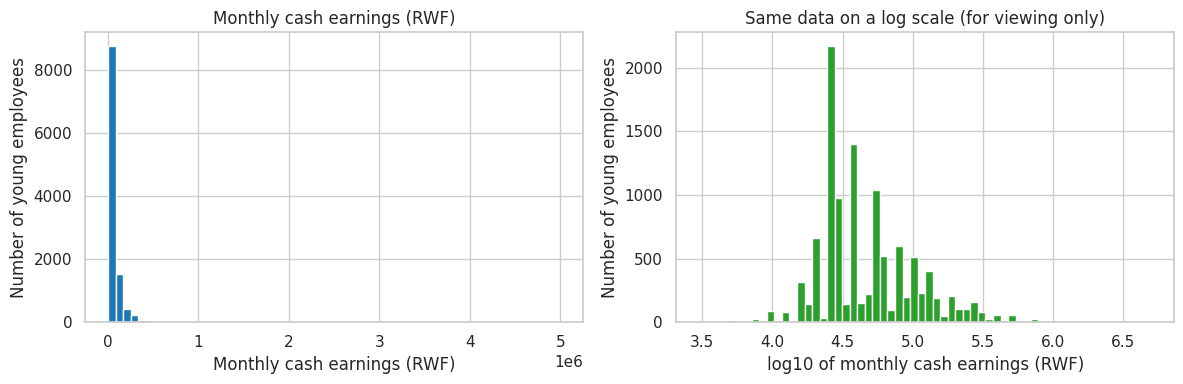

In [ ]:
# Distribution of the target. The right-hand panel uses a log axis for VIEWING only; the model target stays in RWF.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(cash_young_emp.dropna(), bins=60, color="tab:blue", edgecolor="white")
axes[0].set_xlabel("Monthly cash earnings (RWF)")
axes[0].set_ylabel("Number of young employees")
axes[0].set_title("Monthly cash earnings (RWF)")
axes[1].hist(np.log10(cash_young_emp.dropna()), bins=60, color="tab:green", edgecolor="white")
axes[1].set_xlabel("log10 of monthly cash earnings (RWF)")
axes[1].set_ylabel("Number of young employees")
axes[1].set_title("Same data on a log scale (for viewing only)")
plt.tight_layout()
plt.show()

In [ ]:
# Investigate the high earners instead of deleting them
q1, q3 = cash_young_emp.quantile([0.25, 0.75])
iqr_upper_fence = q3 + 1.5 * (q3 - q1)
print(f"IQR upper fence: {iqr_upper_fence:,.0f} RWF; observations above it: {(cash_young_emp > iqr_upper_fence).sum()}")
print()
print(cash_young_emp.quantile([0.90, 0.95, 0.99, 0.999]).rename("percentile value (RWF)").to_frame())
print()
top_earners = stage_cash.nlargest(10, "cash")[["cash", "a04", "b02a", "indd01", "main_sect", "prod_unit", "usual_h"]]
top_earners

IQR upper fence: 156,000 RWF; observations above it: 960

      percentile value (RWF)
0.90              142,880.80
0.95              250,000.00
0.99              520,000.00
1.00            1,500,000.00



,cash,a04,b02a,indd01,main_sect,prod_unit,usual_h
19407,"5,000,000.00",28,Tertiary education,Managers,Services,Formal sector,40.00
38444,"4,000,000.00",28,Tertiary education,Managers,Services,Informal Sector,40.00
830,"3,000,000.00",27,Tertiary education,Professionals,Services,Formal sector,40.00
82565,"2,310,000.00",33,Tertiary education,Professionals,Services,Formal sector,40.00
76333,"2,300,000.00",33,Tertiary education,Managers,Industry,Formal sector,48.00
57462,"2,261,000.00",32,Tertiary education,Managers,Industry,Formal sector,48.00
57475,"2,100,000.00",29,Tertiary education,Professionals,Services,Formal sector,45.00
7043,"2,000,000.00",28,Tertiary education,Professionals,Services,Formal sector,40.00
51138,"2,000,000.00",27,Upper secondary education,Technicians_and_associate_professionals,Services,Formal sector,14.00
19425,"1,950,000.00",29,Upper secondary education,Professionals,Services,Informal Sector,35.00


In [ ]:
# Are high earnings plausible? Compare median pay by occupation group.
(stage_cash.groupby("indd01")["cash"].agg(["count", "median", "mean", "max"])
 .sort_values("median", ascending=False))

,count,median,mean,max
indd01,,,,
Managers,114,"186,000.00","389,989.41","5,000,000.00"
Technicians_and_associate_professionals,201,"180,000.00","255,224.49","2,000,000.00"
Clerical_support_workers,185,"125,000.00","170,736.76","900,000.00"
Professionals,856,"125,000.00","199,974.95","3,000,000.00"
Craft_and_related_trades_workers,830,"120,000.00","129,985.37","780,000.00"
Plant_and_machine_operators_and_assemblers,235,"100,000.00","140,612.77","1,040,000.00"
Service_and_sales_workers,1039,"52,000.00","75,790.27","1,350,000.00"
"Skilled_agricultural,_forestry_and_fishery workers",45,"39,000.00","45,529.26","200,000.00"
Elementary_occupations,7727,"31,200.00","41,513.19","1,040,000.00"


## 6. Filter the population

The model is for **young employees**, so the final modelling table keeps only people who are
1. aged 18 to 35 inclusive (`a04`),
2. classified as `Employee` (`d05`), and
3. have a valid numerical `cash` value.

Missing `cash` is **not** replaced with zero. The missing values belong mostly to people who are not employees (own-account workers, employers and contributing family workers), who were not asked the employee-income question, and zero would wrongly say they earn nothing.

In [ ]:
df_model = df_raw[
    df_raw["a04"].between(18, 35)
    & (df_raw["d05"] == "Employee")
    & df_raw["cash"].notna()
].copy()

print("Final number of valid observations:", len(df_model))
print("Matches the staged count above    :", len(df_model) == len(stage_cash))

Final number of valid observations: 11232
Matches the staged count above    : True


## 7. Exploratory data analysis

The plots below are used to make modelling decisions, not just to decorate the notebook.

First, check which candidate predictors are numerical and which are categorical.

In [ ]:
NUMERICAL_CANDIDATES = ["a04", "usual_h", "d24", "d24b"]
CATEGORICAL_CANDIDATES = ["a01", "b02a", "indd01", "main_sect", "prod_unit", "d08"]

print("Numerical candidates:")
print(df_model[NUMERICAL_CANDIDATES].describe().loc[["count", "min", "50%", "max"]].to_string())
print()
print("Categorical candidates (missing values and number of categories):")
pd.DataFrame({"missing": df_model[CATEGORICAL_CANDIDATES].isna().sum(),
              "number of categories": df_model[CATEGORICAL_CANDIDATES].nunique()})

Numerical candidates:
            a04   usual_h       d24      d24b
count 11,232.00 11,232.00 11,232.00 11,232.00
min       18.00      1.00      0.00      1.00
50%       26.00     36.00      5.00     12.00
max       35.00    120.00     22.00     12.00

Categorical candidates (missing values and number of categories):


,missing,number of categories
a01,0,2
b02a,320,5
indd01,0,9
main_sect,0,3
prod_unit,0,3
d08,3647,7


### Visualisation 1: Correlation heatmap

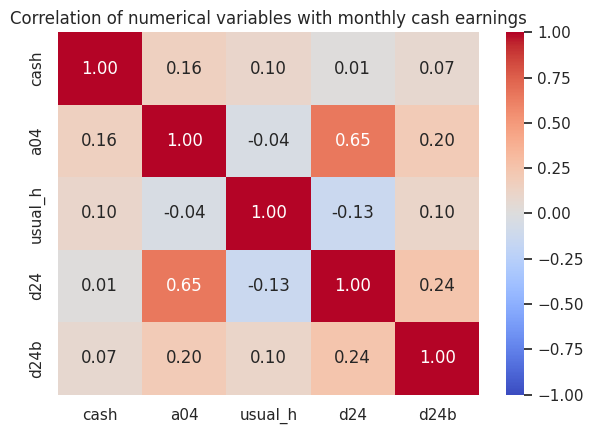

Correlation with cash (strongest first):
a04       0.15
usual_h   0.10
d24b      0.07
d24       0.01


In [ ]:
numeric_for_corr = ["cash"] + NUMERICAL_CANDIDATES
corr_matrix = df_model[numeric_for_corr].corr()

plt.figure(figsize=(6, 4.5))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlation of numerical variables with monthly cash earnings")
plt.tight_layout()
plt.show()

print("Correlation with cash (strongest first):")
print(corr_matrix["cash"].drop("cash").sort_values(key=abs, ascending=False).round(3).to_string())

**What the plot shows and what it means.**

### Visualisation 2: Distributions of the important numerical variables

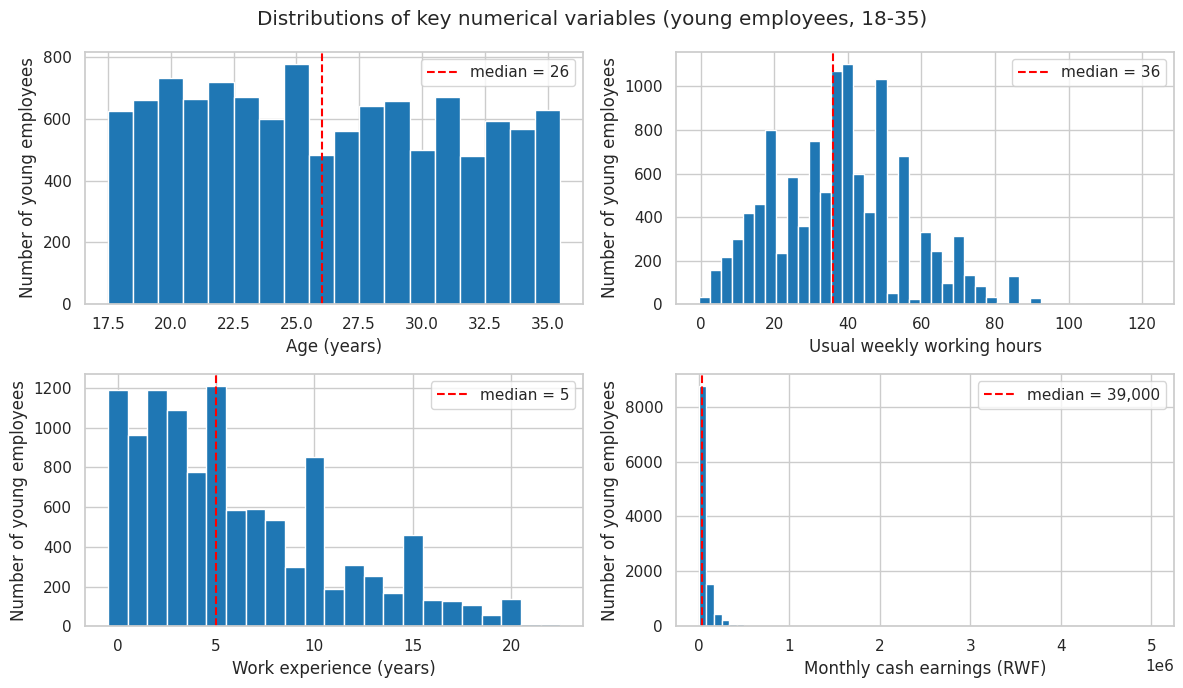

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
plot_specs = [("a04", "Age (years)", np.arange(17.5, 36.5, 1)),
              ("usual_h", "Usual weekly working hours", np.arange(-0.5, 125.5, 3)),
              ("d24", "Work experience (years)", np.arange(-0.5, 23.5, 1)),
              ("cash", "Monthly cash earnings (RWF)", 60)]
for ax, (col, label, bins) in zip(axes.ravel(), plot_specs):
    ax.hist(df_model[col], bins=bins, color="tab:blue", edgecolor="white")
    ax.axvline(df_model[col].median(), color="red", linestyle="--", label=f"median = {df_model[col].median():,.0f}")
    ax.set_xlabel(label)
    ax.set_ylabel("Number of young employees")
    ax.legend()
plt.suptitle("Distributions of key numerical variables (young employees, 18-35)")
plt.tight_layout()
plt.show()

**What the plots show.**

**Decisions.**

### Visualisation 3: Earnings by education, sector and occupation

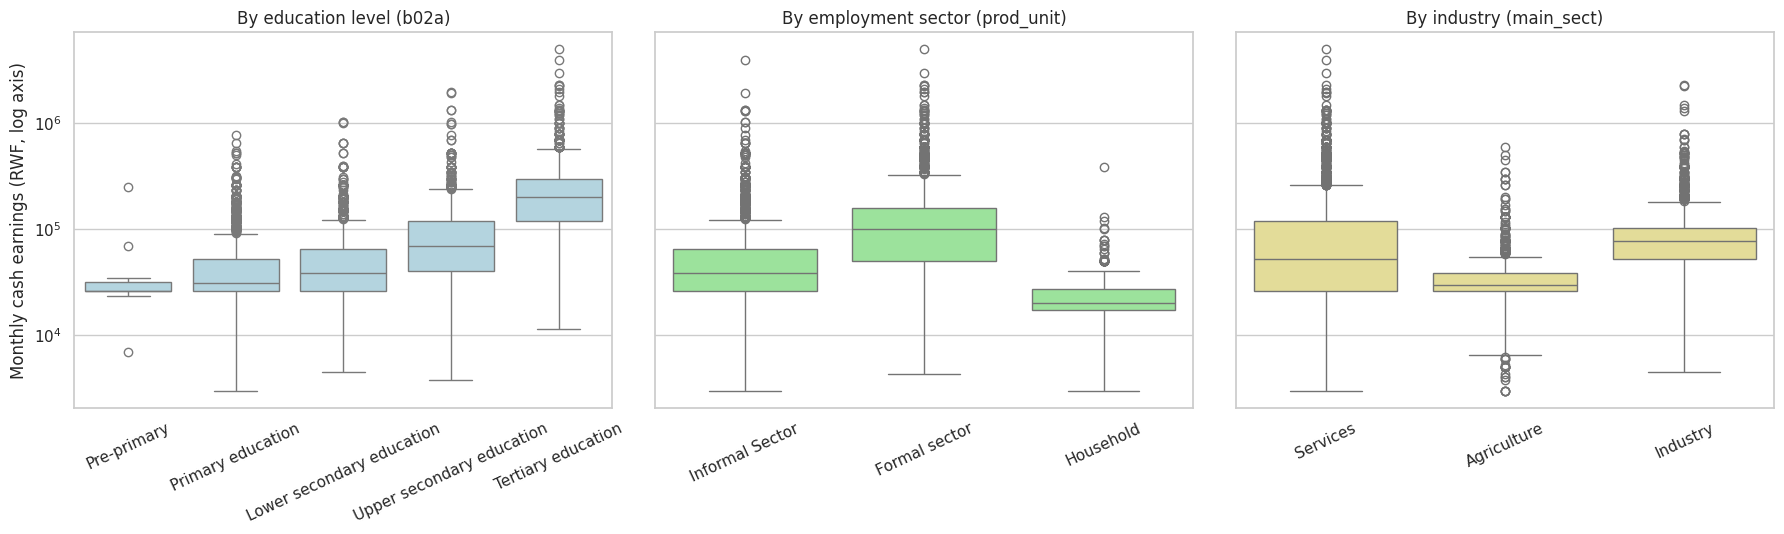

                           count     median
b02a                                       
Pre-primary                   12  26,000.00
Primary education           6178  31,200.00
Lower secondary education   2120  39,000.00
Upper secondary education   1665  70,000.00
Tertiary education           937 200,000.00 

                 count     median
prod_unit                        
Household          950  20,000.00
Informal Sector   7806  39,000.00
Formal sector     2476 100,000.00 

             count    median
main_sect                   
Agriculture   4468 30,000.00
Services      4279 52,000.00
Industry      2485 78,000.00 

        count    median
a01                    
Female   5078 31,200.00
Male     6154 52,000.00 



In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), sharey=True)
order_edu = ["Pre-primary", "Primary education", "Lower secondary education",
             "Upper secondary education", "Tertiary education"]
sns.boxplot(data=df_model, x="b02a", y="cash", order=order_edu, ax=axes[0], color="lightblue")
axes[0].set_title("By education level (b02a)")
sns.boxplot(data=df_model, x="prod_unit", y="cash", ax=axes[1], color="lightgreen")
axes[1].set_title("By employment sector (prod_unit)")
sns.boxplot(data=df_model, x="main_sect", y="cash", ax=axes[2], color="khaki")
axes[2].set_title("By industry (main_sect)")
for ax in axes:
    ax.set_yscale("log")                      # log axis for viewing only
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=25)
axes[0].set_ylabel("Monthly cash earnings (RWF, log axis)")
plt.tight_layout()
plt.show()

# The medians behind the boxes (plus gender, which is also a retained feature)
for col in ["b02a", "prod_unit", "main_sect", "a01"]:
    print(df_model.groupby(col)["cash"].agg(["count", "median"]).sort_values("median").round(0).to_string(), "\n")

**What the plots show.**
**Decisions.**

### Visualisation 4: Contract duration (`d08`) and its missing values
`d08` is missing for a large share of employees. Before deciding how to treat it, check whether *being missing* is related to income.

                           count     median       mean
d08_label                                             
Daily contract/Agreement    6348  39,000.00  55,413.00
Not recorded                3647  50,000.00  97,179.00
One to less than 3 months    362  39,000.00  69,947.00
Less than one month          264  48,400.00  77,139.00
12 to less than 24 months    256 100,000.00 153,847.00
6 to less than 12 months     132  81,000.00 134,721.00
2 years or more              128  76,500.00 165,050.00
3 to less than 6 months       95  80,000.00 114,444.00


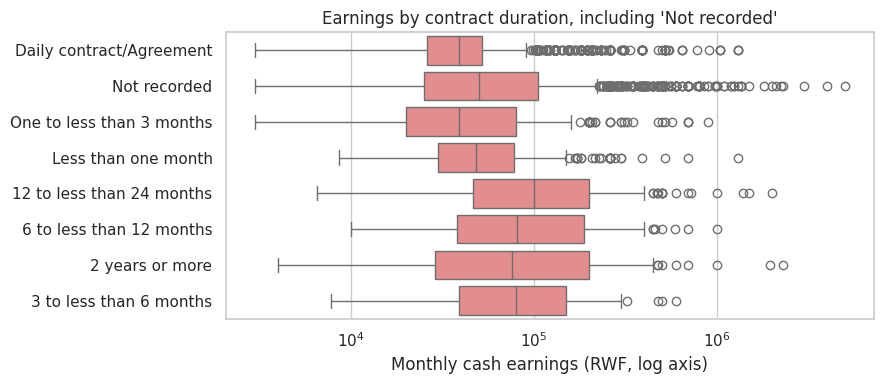

In [ ]:
d08_view = df_model.assign(d08_label=df_model["d08"].fillna("Not recorded"))
d08_summary = (d08_view.groupby("d08_label")["cash"].agg(["count", "median", "mean"])
               .sort_values("count", ascending=False))
print(d08_summary.round(0).to_string())

plt.figure(figsize=(9, 4))
order = d08_summary.index.tolist()
sns.boxplot(data=d08_view, y="d08_label", x="cash", order=order, color="lightcoral")
plt.xscale("log")
plt.xlabel("Monthly cash earnings (RWF, log axis)")
plt.ylabel("")
plt.title("Earnings by contract duration, including 'Not recorded'")
plt.tight_layout()
plt.show()

**What the plot shows.**
**Decision.**

## 8. Feature engineering and selection

### Retained and dropped columns

In [ ]:
retained = pd.DataFrame([
    ("a04", "numerical", "Age", "Retained. Age is a basic driver of pay and has no missing values."),
    ("usual_h", "numerical", "Usual working hours", "Retained. Hours worked directly affect monthly pay."),
    ("d24", "numerical", "Work experience (years)", "Retained. Experience is a standard earnings factor."),
    ("d24b", "numerical", "Months worked per year", "Retained. Seasonal or part-year work reduces monthly cash income."),
    ("a01", "categorical", "Gender", "Retained. Allows the model to reflect gender differences observed in the data."),
    ("b02a", "categorical", "Education level", "Retained. Missing values are filled with a 'Missing' category."),
    ("indd01", "categorical", "Occupation group", "Retained. Strong visible differences in pay between groups."),
    ("main_sect", "categorical", "Industry (agriculture, industry, services)", "Retained."),
    ("prod_unit", "categorical", "Formal / informal / household sector", "Retained. Has variation among employees (checked above)."),
    ("d08", "categorical", "Contract duration", "Retained. Heavy missingness is treated as its own 'Missing' category, not guessed."),
], columns=["column", "type", "meaning", "decision"])
retained

,column,type,meaning,decision
0,a04,numerical,Age,Retained. Age is a basic driver of pay and has...
1,usual_h,numerical,Usual working hours,Retained. Hours worked directly affect monthly...
2,d24,numerical,Work experience (years),Retained. Experience is a standard earnings fa...
3,d24b,numerical,Months worked per year,Retained. Seasonal or part-year work reduces m...
4,a01,categorical,Gender,Retained. Allows the model to reflect gender d...
5,b02a,categorical,Education level,Retained. Missing values are filled with a 'Mi...
6,indd01,categorical,Occupation group,Retained. Strong visible differences in pay be...
7,main_sect,categorical,"Industry (agriculture, industry, services)",Retained.
8,prod_unit,categorical,Formal / informal / household sector,Retained. Has variation among employees (check...
9,d08,categorical,Contract duration,Retained. Heavy missingness is treated as its ...


In [ ]:
dropped = pd.DataFrame([
    ("cash", "Target variable, cannot be a predictor."),
    ("intcash", "Income band derived from the target; including it would leak the answer."),
    ("d05", "Used for filtering. Every remaining row is 'Employee', so it has no variation."),
    ("d10", f"Very limited availability ({df_model['d10'].notna().sum()} non-missing values among the {len(df_model)} modelled employees)."),
    ("d12_1a, d14_1a", "Completely empty in the NISR file."),
    ("psu_no, qh_no, hhid", "Sampling and household identifiers; they do not describe earning potential and could let a model memorise households."),
    ("province, code_ur, code_dis, lfs_strata", "Geographic and sampling-design columns. Outside the candidate pool, so left out to keep the model about personal and job characteristics; location is a possible future improvement."),
    ("attained, isco2digit, isic2digitdigit", "Overlap with b02a, indd01 and main_sect (more categories or more missing values). Kept out for simplicity."),
    ("weight2", "Survey weight, not a characteristic of the person. Not used as a predictor."),
], columns=["column(s)", "reason dropped"])
dropped

,column(s),reason dropped
0,cash,"Target variable, cannot be a predictor."
1,intcash,Income band derived from the target; including...
2,d05,Used for filtering. Every remaining row is 'Em...
3,d10,Very limited availability (892 non-missing val...
4,"d12_1a, d14_1a",Completely empty in the NISR file.
5,"psu_no, qh_no, hhid",Sampling and household identifiers; they do no...
6,"province, code_ur, code_dis, lfs_strata",Geographic and sampling-design columns. Outsid...
7,"attained, isco2digit, isic2digitdigit","Overlap with b02a, indd01 and main_sect (more ..."
8,weight2,"Survey weight, not a characteristic of the per..."


In [ ]:
FEATURES_NUMERICAL = ["a04", "usual_h", "d24", "d24b"]
FEATURES_CATEGORICAL = ["a01", "b02a", "indd01", "main_sect", "prod_unit", "d08"]
FEATURES = FEATURES_NUMERICAL + FEATURES_CATEGORICAL
TARGET = "cash"

print(f"Number of features: {len(FEATURES)} ({len(FEATURES_NUMERICAL)} numerical, {len(FEATURES_CATEGORICAL)} categorical)")

# Final modelling table: only the features and the target
X = df_model[FEATURES].copy()
y = df_model[TARGET].copy()
print("Missing values per feature:")
print(X.isna().sum()[X.isna().sum() > 0].to_string())

Number of features: 10 (4 numerical, 6 categorical)
Missing values per feature:
b02a     320
d08     3647


**Summary of the decisions.**


### Preprocessing design

| Step | Applied to | Technique | Reason |
|---|---|---|---|
| Missing numerical values | `a04`, `usual_h`, `d24`, `d24b` | `SimpleImputer(strategy="median")` | None are missing in this data, but the median is robust to outliers if a future user leaves a value blank. |
| Scaling | numerical features | `StandardScaler` | Puts age (about 18-35) and hours (up to 119) on the same scale. This is essential for gradient descent and harmless for trees. |
| Missing categorical values | categorical features | `SimpleImputer(strategy="constant", fill_value="Missing")` | Keeps "not recorded" as information rather than guessing an education level or contract type. |
| Encoding | categorical features | `OneHotEncoder(handle_unknown="ignore")` | Models need numbers. Unknown categories at prediction time become all zeros instead of crashing the API. |
| Combination | all | `ColumnTransformer` | One object applies the right step to the right column. |

The preprocessor is built here but **fitted only on training data** after the split in the next section.

In [ ]:
def build_preprocessor():
    """Return a fresh, unfitted preprocessing object."""
    numerical_steps = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ])
    categorical_steps = Pipeline([
        ("impute", SimpleImputer(strategy="constant", fill_value="Missing")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    return ColumnTransformer([
        ("numerical", numerical_steps, FEATURES_NUMERICAL),
        ("categorical", categorical_steps, FEATURES_CATEGORICAL),
    ])

preprocessor_template = build_preprocessor()
preprocessor_template

ColumnTransformer(transformers=[('numerical',
                                 Pipeline(steps=[('impute',
                                                  SimpleImputer(strategy='median')),
                                                 ('scale', StandardScaler())]),
                                 ['a04', 'usual_h', 'd24', 'd24b']),
                                ('categorical',
                                 Pipeline(steps=[('impute',
                                                  SimpleImputer(fill_value='Missing',
                                                                strategy='constant')),
                                                 ('onehot',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False))]),
                                 ['a01', 'b02a', 'indd01', 'main_sect',
                                  'prod_unit', 'd08'])])

## 9. Train/test split

An 80/20 split with a fixed seed. **Every model uses these same four objects** (`X_train`, `X_test`, `y_train`, `y_test`). The test set is held back for the final comparison only. Hyperparameters are chosen using validation data taken **from the training set**, so the test set is not used for tuning.

In [ ]:

# Divide earnings into 10 quantile-based groups
earnings_groups = pd.qcut(y, q=10, labels=False, duplicates="drop")

# Split into training and testing sets while preserving earnings-group proportions
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE,
    stratify=earnings_groups
)

print("Training rows:", len(X_train), "| Testing rows:", len(X_test))

# Fit preprocessing on training data only
preprocessor = build_preprocessor().fit(X_train)
X_train_t = preprocessor.transform(X_train)
X_test_t = preprocessor.transform(X_test)

print("Transformed training matrix shape:", X_train_t.shape)
print("Median cash, train vs test:", f"{y_train.median():,.0f} vs {y_test.median():,.0f} RWF")
print("Std. dev. of cash, train vs test:", f"{y_train.std():,.0f} vs {y_test.std():,.0f} RWF")
print("Largest cash value in train vs test:", f"{y_train.max():,.0f} vs {y_test.max():,.0f} RWF")


Training rows: 8985 | Testing rows: 2247
Transformed training matrix shape: (8985, 35)
Median cash, train vs test: 39,000 vs 39,000 RWF
Std. dev. of cash, train vs test: 136,155 vs 119,428 RWF
Largest cash value in train vs test: 5,000,000 vs 2,261,000 RWF


In [ ]:
# Helper used for every model: MSE on a given dataset
def mse(model, X_data, y_data):
    return mean_squared_error(y_data, model.predict(X_data))

## 10. SGDRegressor (linear regression by gradient descent)

`SGDRegressor` fits the same kind of linear model as ordinary least squares, but **iteratively**: it looks at the training rows one at a time and nudges the coefficients in the direction that reduces the squared error. One pass through the training data is one **epoch**.

### Hyperparameters tuned
- **Learning rate:** the schedule (`constant` or `invscaling`) and its starting value `eta0`. Too large and the coefficients bounce around or diverge; too small and learning is slow.
- **Regularisation strength `alpha`:** an L2 penalty that shrinks coefficients. It guards against overfitting but, if too large, makes the model too simple.
- **Number of epochs:** how many passes over the data. Too few underfits; too many can overfit or just add noise.

### Tuning without touching the test set
The training data is split again into a sub-training set (80%) and a **validation set** (20%). Each setting is trained for up to 500 epochs with `partial_fit()` (one call = one epoch). The preprocessor is refitted on the sub-training data only, so the validation set is also kept clean. The combination with the lowest validation MSE is chosen.

In [ ]:

# Validation split carved out of the TRAINING data only
sub_groups = earnings_groups.loc[X_train.index]

X_sub, X_val, y_sub, y_val = train_test_split(
    X_train, y_train,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=sub_groups
)

# Fit preprocessing on sub-training data only
prep_sub = build_preprocessor().fit(X_sub)
X_sub_t, X_val_t = prep_sub.transform(X_sub), prep_sub.transform(X_val)

MAX_TUNING_EPOCHS = 500
search_rows = []

for schedule in ["constant", "invscaling"]:
    for eta0 in [1e-4, 1e-3, 1e-2, 5e-2]:
        for alpha in [1e-6, 1e-4, 1e-2, 1.0, 100.0]:
            sgd = SGDRegressor(
                loss="squared_error",
                penalty="l2",
                alpha=alpha,
                learning_rate=schedule,
                eta0=eta0,
                random_state=RANDOM_STATE
            )

            val_curve = []

            with warnings.catch_warnings(), np.errstate(all="ignore"):
                warnings.simplefilter("ignore")

                for epoch in range(MAX_TUNING_EPOCHS):
                    sgd.partial_fit(X_sub_t, y_sub)
                    val_curve.append(mse(sgd, X_val_t, y_val))

            val_curve = np.array(val_curve, dtype=float)
            val_curve[~np.isfinite(val_curve)] = np.inf

            search_rows.append({
                "learning_rate": schedule,
                "eta0": eta0,
                "alpha": alpha,
                "best_epoch": int(val_curve.argmin()) + 1,
                "best_validation_MSE": val_curve.min()
            })

sgd_search = pd.DataFrame(search_rows).sort_values(
    "best_validation_MSE"
).reset_index(drop=True)

pd.set_option("display.float_format", lambda v: f"{v:,.4g}" if abs(v) < 1 else f"{v:,.0f}")
display(sgd_search.head(8))

pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

print("Best validation MSE reached at each regularisation strength (alpha):")
print(
    sgd_search.groupby("alpha")["best_validation_MSE"]
    .min()
    .rename(index=lambda a: f"{a:g}")
    .map("{:,.0f}".format)
    .to_string()
)


,learning_rate,eta0,alpha,best_epoch,best_validation_MSE
0,invscaling,0.01,1e-06,494,"19,343,083,399"
1,invscaling,0.01,0.0001,490,"19,344,697,942"
2,constant,0.001,1e-06,500,"19,348,562,019"
3,constant,0.001,0.0001,500,"19,350,240,327"
4,invscaling,0.05,1e-06,500,"19,350,471,340"
5,invscaling,0.05,0.0001,500,"19,352,157,210"
6,constant,0.0001,1e-06,500,"19,352,991,609"
7,constant,0.0001,0.0001,500,"19,354,416,254"


Best validation MSE reached at each regularisation strength (alpha):
alpha
1e-06     19,343,083,399
0.0001    19,344,697,942
0.01      19,511,498,995
1         22,561,008,816
100       24,966,450,292


In [ ]:
best_sgd = sgd_search.iloc[0]
SGD_PARAMS = {"learning_rate": str(best_sgd["learning_rate"]), "eta0": float(best_sgd["eta0"]), "alpha": float(best_sgd["alpha"])}
SGD_EPOCHS = int(best_sgd["best_epoch"])
print("Chosen by validation MSE:", SGD_PARAMS, "| epochs:", SGD_EPOCHS)

Chosen by validation MSE: {'learning_rate': 'invscaling', 'eta0': 0.01, 'alpha': 1e-06} | epochs: 494


**What the search shows.**
**Why these values make sense, and a caveat.**

### Final SGDRegressor training with per-epoch loss recording
Now train on the **full training set** with the chosen settings. After each `partial_fit()` call (one epoch) the training MSE and testing MSE are recorded. The recorded test curve is for **reporting and the loss-curve plot only**; the settings above were already chosen from validation data. The loop runs for 300 epochs, longer than the validated number, so the curve also shows what happens beyond the chosen stopping point.

In [ ]:
PLOT_EPOCHS = 500
sgd_model = SGDRegressor(loss="squared_error", penalty="l2", random_state=RANDOM_STATE, **SGD_PARAMS)

train_mse_per_epoch, test_mse_per_epoch = [], []
snapshot_at_chosen_epoch = None
for epoch in range(1, PLOT_EPOCHS + 1):
    sgd_model.partial_fit(X_train_t, y_train)                   # exactly one pass over the training data
    train_mse_per_epoch.append(mse(sgd_model, X_train_t, y_train))
    test_mse_per_epoch.append(mse(sgd_model, X_test_t, y_test))
    if epoch == SGD_EPOCHS:                                      # keep the model at the validated epoch count
        snapshot_at_chosen_epoch = copy.deepcopy(sgd_model)

print(f"Epoch 1   : train MSE {train_mse_per_epoch[0]:,.0f} | test MSE {test_mse_per_epoch[0]:,.0f}")
print(f"Epoch {SGD_EPOCHS:<3}: train MSE {train_mse_per_epoch[SGD_EPOCHS-1]:,.0f} | test MSE {test_mse_per_epoch[SGD_EPOCHS-1]:,.0f}  (validated stopping point)")
print(f"Epoch {PLOT_EPOCHS}: train MSE {train_mse_per_epoch[-1]:,.0f} | test MSE {test_mse_per_epoch[-1]:,.0f}")

Epoch 1   : train MSE 13,823,853,642 | test MSE 9,910,862,629
Epoch 494: train MSE 13,205,495,540 | test MSE 9,341,198,578  (validated stopping point)
Epoch 500: train MSE 13,205,457,410 | test MSE 9,341,160,187


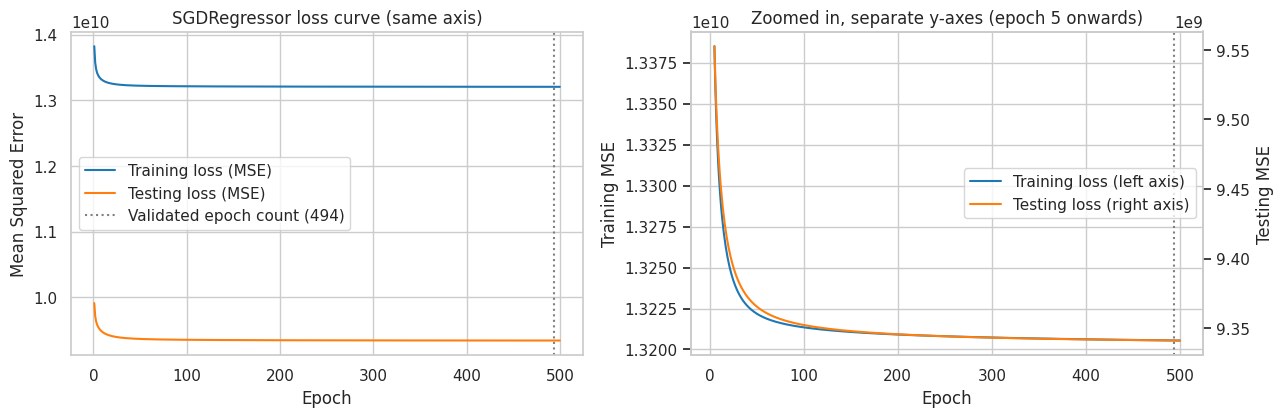

Epoch with the lowest testing MSE: 500 (9,341,160,187)
Change in training MSE between epoch 494 and epoch 500: -0.0003%


In [ ]:
# Required loss curve: training and testing MSE per epoch on the same chart (left panel)
epochs = np.arange(1, PLOT_EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(epochs, train_mse_per_epoch, label="Training loss (MSE)", color="tab:blue")
axes[0].plot(epochs, test_mse_per_epoch, label="Testing loss (MSE)", color="tab:orange")
axes[0].axvline(SGD_EPOCHS, color="grey", linestyle=":", label=f"Validated epoch count ({SGD_EPOCHS})")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Mean Squared Error")
axes[0].set_title("SGDRegressor loss curve (same axis)")
axes[0].legend()

# Right panel: zoom from epoch 5 with a separate y-axis per curve, so small changes become visible
ax_train = axes[1]
ax_test = ax_train.twinx()
line_train = ax_train.plot(epochs[4:], train_mse_per_epoch[4:], color="tab:blue", label="Training loss (left axis)")
line_test = ax_test.plot(epochs[4:], test_mse_per_epoch[4:], color="tab:orange", label="Testing loss (right axis)")
ax_train.axvline(SGD_EPOCHS, color="grey", linestyle=":")
ax_train.set_xlabel("Epoch")
ax_train.set_ylabel("Training MSE")
ax_test.set_ylabel("Testing MSE")
ax_test.grid(False)
ax_train.set_title("Zoomed in, separate y-axes (epoch 5 onwards)")
ax_train.legend(line_train + line_test, [l.get_label() for l in line_train + line_test], loc="center right")
plt.tight_layout()
plt.show()

best_test_epoch = int(np.argmin(test_mse_per_epoch)) + 1
print(f"Epoch with the lowest testing MSE: {best_test_epoch} ({min(test_mse_per_epoch):,.0f})")
print(f"Change in training MSE between epoch {SGD_EPOCHS} and epoch {PLOT_EPOCHS}: "
      f"{(train_mse_per_epoch[-1] / train_mse_per_epoch[SGD_EPOCHS - 1] - 1):.4%}")

**What the plot shows.**
**Interpretation.**

In [ ]:
# The SGD model used in the final comparison is the one at the validated epoch count
sgd_pipeline = Pipeline([("preprocessor", preprocessor), ("model", snapshot_at_chosen_epoch)])
print("SGD pipeline MSE (train):", f"{mse(sgd_pipeline, X_train, y_train):,.0f}")
print("SGD pipeline MSE (test) :", f"{mse(sgd_pipeline, X_test, y_test):,.0f}")

SGD pipeline MSE (train): 13,205,495,540
SGD pipeline MSE (test) : 9,341,198,578


## 11. LinearRegression (closed-form)

`LinearRegression` solves ordinary least squares **directly** with linear algebra (the normal equation / a matrix decomposition). There is no learning rate, no epochs and no randomness: it computes, in one step, the coefficients that minimise the training squared error.

| | `SGDRegressor` | `LinearRegression` |
|---|---|---|
| Method | Iterative gradient descent | Exact closed-form solution |
| Hyperparameters | Learning rate, `alpha`, epochs | None |
| Regularisation | L2 penalty via `alpha` | None |
| Result | Approximation that depends on the settings | The least-squares optimum for the training data |

Both fit the same kind of straight-line (linear) relationship. The closed-form result is the benchmark the gradient-descent model is trying to reach.

In [ ]:
lr_pipeline = Pipeline([("preprocessor", build_preprocessor()), ("model", LinearRegression())])
lr_pipeline.fit(X_train, y_train)
print("LinearRegression MSE (train):", f"{mse(lr_pipeline, X_train, y_train):,.0f}")
print("LinearRegression MSE (test) :", f"{mse(lr_pipeline, X_test, y_test):,.0f}")

LinearRegression MSE (train): 13,199,752,840
LinearRegression MSE (test) : 9,334,067,731


**Result and comparison.** The closed-form model reaches the lowest possible training MSE for a linear model (13.769 billion, just below SGD's 13.775 billion), as expected from an exact least-squares solution. On the test set it is also marginally lower (7.0635 billion against 7.0696 billion for SGD), a difference of about 0.09%. The two linear implementations are therefore effectively identical, which is a useful correctness check: the gradient-descent model has converged to the least-squares solution. The tiny difference should not be read as one algorithm being better than the other.

## 12. DecisionTreeRegressor

A decision tree learns a sequence of yes/no questions (for example *"is the occupation group elementary?"* then *"are usual hours above 40?"*) that split young employees into groups, and predicts the **average income of the group** each person lands in. It can capture non-linear effects and interactions that a straight-line model cannot.

An unrestricted tree keeps splitting until each leaf holds almost one person, which memorises the training data (overfitting). Three settings control this:
- `max_depth`: the maximum number of questions in a row.
- `min_samples_split`: how many people a group needs before it may be split.
- `min_samples_leaf`: the minimum number of people allowed in a final group.

These are tuned with 5-fold cross-validation on the **training set only**. Preprocessing is inside the pipeline, so it is refitted within every fold.

In [ ]:
dt_search = GridSearchCV(
    Pipeline([("preprocessor", build_preprocessor()),
              ("model", DecisionTreeRegressor(random_state=RANDOM_STATE))]),
    param_grid={"model__max_depth": [3, 5, 8, 12, None],
                "model__min_samples_split": [2, 10, 50, 100],
                "model__min_samples_leaf": [1, 5, 20, 50]},
    scoring="neg_mean_squared_error", cv=5, n_jobs=-1,
)
dt_search.fit(X_train, y_train)
dt_pipeline = dt_search.best_estimator_

print("Best parameters:", dt_search.best_params_)
print("Cross-validated MSE:", f"{-dt_search.best_score_:,.0f}")
print("DecisionTree MSE (train):", f"{mse(dt_pipeline, X_train, y_train):,.0f}")
print("DecisionTree MSE (test) :", f"{mse(dt_pipeline, X_test, y_test):,.0f}")

Best parameters: {'model__max_depth': 5, 'model__min_samples_leaf': 5, 'model__min_samples_split': 100}
Cross-validated MSE: 13,182,010,128
DecisionTree MSE (train): 12,028,706,012
DecisionTree MSE (test) : 8,875,347,025


**Result.** Cross-validation chose a shallow tree (`max_depth = 5`, `min_samples_leaf = 5`, `min_samples_split = 50`), meaning at most 32 groups, with no group smaller than 5 people. These limits keep the tree from memorising individual rows and are inside the search grid, not at its edge. The tree has a training MSE of 12.09 billion and a test MSE of 9.07 billion, the highest test MSE of the four models and a test R-squared of only 0.24. A single tree is unstable: a few high earners inside one group can shift its prediction a lot.

## 13. RandomForestRegressor

A random forest builds many decision trees, each on a random resample of the training rows with randomised splits, and **averages their predictions**. Averaging many different trees cancels out much of the overfitting of a single tree. Parameters tuned: `n_estimators` (number of trees), `max_depth`, `min_samples_split` and `min_samples_leaf`. Tuning uses 3-fold cross-validation on the training set only, with a fixed `random_state`.

In [ ]:
rf_search = GridSearchCV(
    Pipeline([("preprocessor", build_preprocessor()),
              ("model", RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1))]),
    param_grid={"model__n_estimators": [100, 200, 300],
                "model__max_depth": [8, None],
                "model__min_samples_split": [2, 10],
                "model__min_samples_leaf": [1, 5, 10]},
    scoring="neg_mean_squared_error", cv=3, n_jobs=1,
)
rf_search.fit(X_train, y_train)
rf_pipeline = rf_search.best_estimator_

print("Best parameters:", rf_search.best_params_)
print("Cross-validated MSE:", f"{-rf_search.best_score_:,.0f}")
print("RandomForest MSE (train):", f"{mse(rf_pipeline, X_train, y_train):,.0f}")
print("RandomForest MSE (test) :", f"{mse(rf_pipeline, X_test, y_test):,.0f}")

Best parameters: {'model__max_depth': None, 'model__min_samples_leaf': 10, 'model__min_samples_split': 2, 'model__n_estimators': 100}
Cross-validated MSE: 12,878,226,821
RandomForest MSE (train): 10,427,469,472
RandomForest MSE (test) : 8,703,068,668


**Result.** Cross-validation chose 200 trees limited to `max_depth = 8`, with `min_samples_leaf = 5` and `min_samples_split = 2`. The forest has a training MSE of 9.85 billion and a test MSE of 8.20 billion, better than the single tree but worse than the two linear models on this split (test R-squared 0.31). Because the trees are depth-limited, it overfits far less than a fully grown forest would, and averaging many trees gives it the lowest MAE of all models (about 36,100 RWF), but it does not capture the largest earners as well as the linear models do.

## 14. Model comparison

All four models are evaluated on exactly the same training and testing rows. **Mean Squared Error** is the average of the squared differences between actual and predicted earnings. Its unit is RWF squared, so the numbers are very large and hard to read directly; the square root (RMSE) and mean absolute error (MAE) below give the same information in plain RWF. Because MSE squares each error, it is **very sensitive to a few very high earners**.

In [ ]:
fitted_pipelines = {
    "SGDRegressor": sgd_pipeline,
    "LinearRegression": lr_pipeline,
    "DecisionTreeRegressor": dt_pipeline,
    "RandomForestRegressor": rf_pipeline,
}

comparison = pd.DataFrame({
    name: {"Training MSE": mse(p, X_train, y_train), "Testing MSE": mse(p, X_test, y_test)}
    for name, p in fitted_pipelines.items()
}).T
comparison["Test / Train MSE ratio"] = comparison["Testing MSE"] / comparison["Training MSE"]
comparison.index.name = "Model"

display(comparison.style.format({"Training MSE": "{:,.0f}", "Testing MSE": "{:,.0f}", "Test / Train MSE ratio": "{:.2f}"}))

,Training MSE,Testing MSE,Test / Train MSE ratio
Model,,,
SGDRegressor,"13,205,495,540","9,341,198,578",0.71
LinearRegression,"13,199,752,840","9,334,067,731",0.71
DecisionTreeRegressor,"12,028,706,012","8,875,347,025",0.74
RandomForestRegressor,"10,427,469,472","8,703,068,668",0.83


In [ ]:
# The same models in plain RWF units (supplementary; the assignment metric is MSE)
supplementary = pd.DataFrame({
    name: {"Test RMSE (RWF)": np.sqrt(mse(p, X_test, y_test)),
           "Test MAE (RWF)": mean_absolute_error(y_test, p.predict(X_test)),
           "Test R-squared": r2_score(y_test, p.predict(X_test))}
    for name, p in fitted_pipelines.items()
}).T
print(f"For reference, the standard deviation of test earnings is {y_test.std():,.0f} RWF "
      f"and the median is {y_test.median():,.0f} RWF.")
display(supplementary.style.format({"Test RMSE (RWF)": "{:,.0f}", "Test MAE (RWF)": "{:,.0f}", "Test R-squared": "{:.3f}"}))

For reference, the standard deviation of test earnings is 119,428 RWF and the median is 39,000 RWF.


,Test RMSE (RWF),Test MAE (RWF),Test R-squared
SGDRegressor,"96,650","38,733",0.345
LinearRegression,"96,613","38,122",0.345
DecisionTreeRegressor,"94,209","37,287",0.377
RandomForestRegressor,"93,290","35,886",0.390


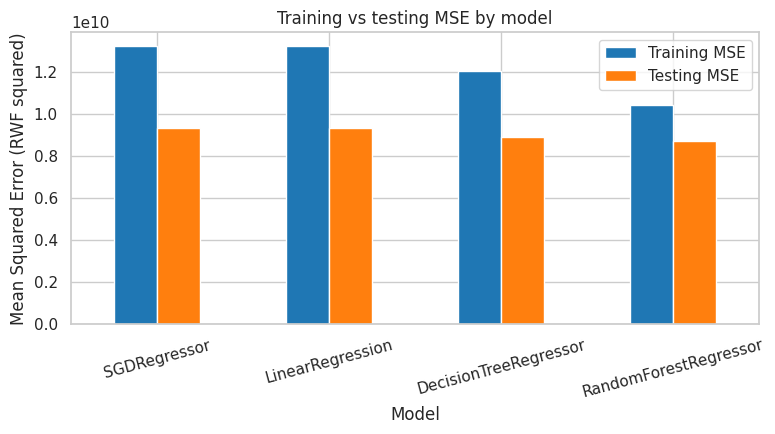

In [ ]:
# Visual comparison of training and testing MSE
comparison[["Training MSE", "Testing MSE"]].plot(kind="bar", figsize=(8, 4.5), color=["tab:blue", "tab:orange"])
plt.ylabel("Mean Squared Error (RWF squared)")
plt.title("Training vs testing MSE by model")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

**Reading the table.**
- **Test MSE is lower than training MSE for every model**
- **Linear models**
- **Decision tree**
- **Random forest**

**MSE and outliers.**

In [ ]:
# How much of the best model's test MSE comes from a handful of extreme errors?
best_by_mse = comparison["Testing MSE"].idxmin()
squared_errors = (y_test - fitted_pipelines[best_by_mse].predict(X_test)) ** 2
n_top = max(1, int(0.01 * len(squared_errors)))
print(f"{best_by_mse}: the largest {n_top} squared errors (top 1% of test rows) account for "
      f"{squared_errors.nlargest(n_top).sum() / squared_errors.sum():.0%} of the total test squared error.")
print(f"The largest 10 account for {squared_errors.nlargest(10).sum() / squared_errors.sum():.0%}.")

RandomForestRegressor: the largest 22 squared errors (top 1% of test rows) account for 66% of the total test squared error.
The largest 10 account for 51%.


### Robustness check: household-aware split
The survey interviews whole households, so two members of one household can land in both the training and the test set under a plain random split. That could make the test results slightly optimistic. As a **check only** (the official comparison above stays on the required random split), the three models that do not need the epoch loop are refitted with their chosen settings on a split that keeps each household (`hhid`) entirely on one side.

In [ ]:
from sklearn.model_selection import GroupShuffleSplit

households = (df_model.loc[X.index, "psu_no"].astype(str) + "_" + df_model.loc[X.index, "qh_no"].astype(str) + "_" + df_model.loc[X.index, "hhid"].astype(str))
group_train_idx, group_test_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_STATE).split(X, y, households))
Xg_train, Xg_test = X.iloc[group_train_idx], X.iloc[group_test_idx]
yg_train, yg_test = y.iloc[group_train_idx], y.iloc[group_test_idx]
print("Households shared between train and test:", len(set(households.iloc[group_train_idx]) & set(households.iloc[group_test_idx])))

check_models = {
    "LinearRegression": clone(lr_pipeline),
    "DecisionTreeRegressor": clone(dt_pipeline),          # clone keeps the tuned settings, drops the fitted state
    "RandomForestRegressor": clone(rf_pipeline),
}
robustness = pd.DataFrame({
    name: {"Testing MSE, random split": comparison.loc[name, "Testing MSE"],
           "Testing MSE, household split": mse(m.fit(Xg_train, yg_train), Xg_test, yg_test)}
    for name, m in check_models.items()
}).T
display(robustness.style.format("{:,.0f}"))

Households shared between train and test: 0


,"Testing MSE, random split","Testing MSE, household split"
LinearRegression,"9,334,067,731","9,396,347,357"
DecisionTreeRegressor,"8,875,347,025","10,222,536,897"
RandomForestRegressor,"8,703,068,668","8,416,692,230"


### Cross-validation check
One split is a thin basis for ranking models when a few extreme earners decide the score, so the same three models (with their tuned settings) are also scored with 5-fold cross-validation on all modelled rows, both with ordinary shuffled folds and with folds that keep each household together. The mean and spread across folds show how stable each model's error is. This is a robustness check only (the hyperparameters were chosen on the training rows, so these figures are slightly optimistic for the tuned tree and forest).

In [ ]:
from sklearn.model_selection import GroupKFold, KFold, cross_val_score

cv_rows = {}
for name in ["LinearRegression", "DecisionTreeRegressor", "RandomForestRegressor"]:
    estimator = clone(fitted_pipelines[name])
    shuffled = -cross_val_score(estimator, X, y, cv=KFold(5, shuffle=True, random_state=RANDOM_STATE),
                                scoring="neg_mean_squared_error")
    grouped = -cross_val_score(estimator, X, y, cv=GroupKFold(n_splits=5), groups=households,
                               scoring="neg_mean_squared_error")
    cv_rows[name] = {"Shuffled 5-fold: mean MSE": shuffled.mean(), "Shuffled 5-fold: std": shuffled.std(),
                     "Household 5-fold: mean MSE": grouped.mean(), "Household 5-fold: std": grouped.std()}
display(pd.DataFrame(cv_rows).T.style.format("{:,.0f}"))

,Shuffled 5-fold: mean MSE,Shuffled 5-fold: std,Household 5-fold: mean MSE,Household 5-fold: std
LinearRegression,"12,602,352,479","3,812,494,036","12,826,044,897","7,388,489,151"
DecisionTreeRegressor,"12,758,413,286","2,919,397,847","12,633,941,850","6,303,015,281"
RandomForestRegressor,"12,122,364,725","2,660,350,809","12,808,816,962","6,460,951,716"


**Household-aware split.**
**Cross-validation.**
**What this means.**

## 15. Select the best model

**Selection criterion:** the model with the **lowest testing MSE** is the best model. Testing MSE is computed on data the model never saw during training or tuning, so it is the fairest estimate of how the model will perform on new young employees. Training MSE alone is not used, because a model can score well on it by memorising.

In [ ]:
best_name = comparison["Testing MSE"].idxmin()
best_pipeline = fitted_pipelines[best_name]

print(f"Best model by testing MSE: {best_name}")
print(f"  Training MSE: {comparison.loc[best_name, 'Training MSE']:,.0f}")
print(f"  Testing MSE : {comparison.loc[best_name, 'Testing MSE']:,.0f}")
print()
print("Testing MSE of each model relative to the best (1.00 = best):")
print((comparison["Testing MSE"] / comparison.loc[best_name, "Testing MSE"]).sort_values().round(3).to_string())

Best model by testing MSE: RandomForestRegressor
  Training MSE: 10,427,469,472
  Testing MSE : 8,703,068,668

Testing MSE of each model relative to the best (1.00 = best):
Model
RandomForestRegressor   1.00
DecisionTreeRegressor   1.02
LinearRegression        1.07
SGDRegressor            1.07


**Selection.**

**Why it was selected, and its limits.**

## 16. Scatter plot before training the line

Find the numerical feature most strongly correlated with `cash` (absolute Pearson correlation) and plot it against monthly earnings. The correlation is computed on the **training data**.

In [ ]:
train_corr = pd.concat([X_train[FEATURES_NUMERICAL], y_train], axis=1).corr()[TARGET].drop(TARGET)
top_feature = train_corr.abs().idxmax()
print("Correlation of each numerical feature with cash (training data):")
print(train_corr.round(3).to_string())
print(f"\nMost strongly correlated numerical feature: {top_feature} (r = {train_corr[top_feature]:.3f})")

Correlation of each numerical feature with cash (training data):
a04       0.15
usual_h   0.09
d24       0.01
d24b      0.07

Most strongly correlated numerical feature: a04 (r = 0.149)


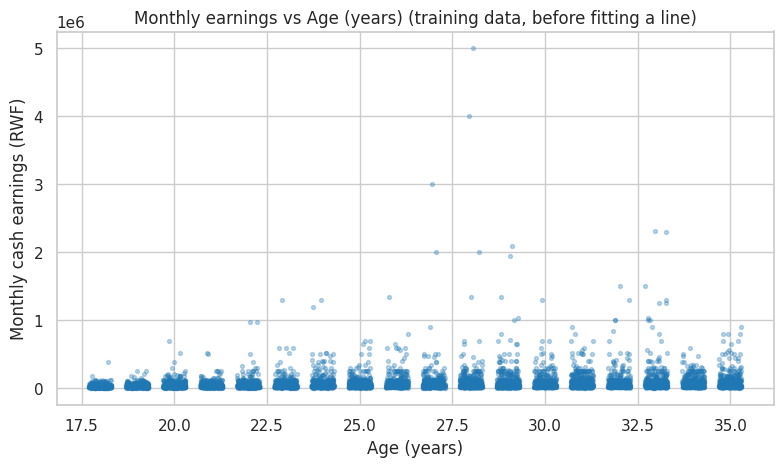

In [ ]:
FEATURE_LABELS = {"a04": "Age (years)", "usual_h": "Usual weekly working hours",
                  "d24": "Work experience (years)", "d24b": "Months worked per year"}
feature_label = FEATURE_LABELS[top_feature]

rng = np.random.default_rng(RANDOM_STATE)
jitter = rng.uniform(-0.3, 0.3, size=len(X_train))           # small horizontal jitter so overlapping points are visible

plt.figure(figsize=(8, 5))
plt.scatter(X_train[top_feature] + jitter, y_train, s=8, alpha=0.3, color="tab:blue")
plt.xlabel(feature_label)
plt.ylabel("Monthly cash earnings (RWF)")
plt.title(f"Monthly earnings vs {feature_label} (training data, before fitting a line)")
plt.tight_layout()
plt.show()

**What the plot shows.**

**Observation and decision.**

## 17. Scatter plot after training, with the fitted regression line

The same scatter plot, now with a line from a **one-feature `LinearRegression`** model fitted to the selected feature alone.

**Important:** this one-feature model exists only to draw the line on a two-dimensional chart. It is a visualisation tool and is **not** one of the four multivariate models being compared, nor a replacement for them. The multivariate models use all ten features.

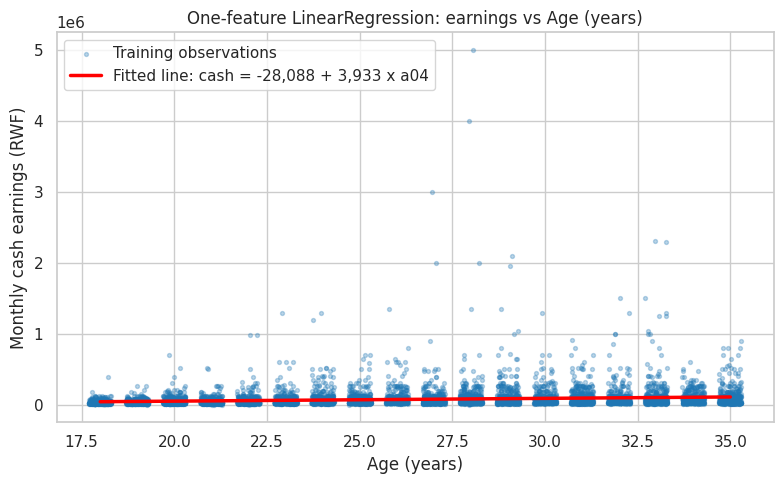

Slope: 3,933 RWF per unit of a04
One-feature model R-squared on training data: 0.022
One-feature model test MSE: 13,782,244,176


In [ ]:
# One-feature linear regression, used only for the visualisation
line_model = LinearRegression()
line_model.fit(X_train[[top_feature]], y_train)

x_grid = np.linspace(X_train[top_feature].min(), X_train[top_feature].max(), 100).reshape(-1, 1)
x_grid_df = pd.DataFrame(x_grid, columns=[top_feature])
y_line = line_model.predict(x_grid_df)

plt.figure(figsize=(8, 5))
plt.scatter(X_train[top_feature] + jitter, y_train, s=8, alpha=0.3, color="tab:blue", label="Training observations")
plt.plot(x_grid, y_line, color="red", linewidth=2.5,
         label=f"Fitted line: cash = {line_model.intercept_:,.0f} + {line_model.coef_[0]:,.0f} x {top_feature}")
plt.xlabel(feature_label)
plt.ylabel("Monthly cash earnings (RWF)")
plt.title(f"One-feature LinearRegression: earnings vs {feature_label}")
plt.legend()
plt.tight_layout()
plt.show()

print(f"Slope: {line_model.coef_[0]:,.0f} RWF per unit of {top_feature}")
print(f"One-feature model R-squared on training data: {line_model.score(X_train[[top_feature]], y_train):.3f}")
print(f"One-feature model test MSE: {mean_squared_error(y_test, line_model.predict(X_test[[top_feature]])):,.0f}")

**What the plot shows.**
**Why this is not a replacement for the main models.**

## 18. Save the best model

The saved file is a complete scikit-learn `Pipeline` that holds the **fitted preprocessing** and the **fitted best model**. It accepts raw feature values (text categories, unscaled numbers, blanks) and does the imputing, encoding and scaling itself. A small JSON file with the feature list and allowed category values is saved alongside it to help the later API and Flutter form.

In [ ]:
MODEL_PATH = "best_model.joblib"
joblib.dump(best_pipeline, MODEL_PATH, compress=3)   # compress=3 keeps the file small; loading is unchanged

# Metadata to help the future API (input names, categories, versions); not needed to load the model
metadata = {
    "best_model": best_name,
    "target": TARGET,
    "target_unit": "RWF per month",
    "numerical_features": FEATURES_NUMERICAL,
    "categorical_features": FEATURES_CATEGORICAL,
    "categorical_values": {c: sorted(X_train[c].dropna().unique().tolist()) for c in FEATURES_CATEGORICAL},
    "numerical_ranges": {c: [float(X_train[c].min()), float(X_train[c].max())] for c in FEATURES_NUMERICAL},
    "sklearn_version": sklearn.__version__,
}
with open("model_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)
print("Saved:", MODEL_PATH, f"({Path(MODEL_PATH).stat().st_size / 1e3:,.0f} KB) and model_metadata.json")

Saved: best_model.joblib (2,100 KB) and model_metadata.json


In [ ]:
# Test the saved pipeline BEFORE trusting it: reload it and confirm it gives the same predictions as the in-memory model
reloaded = joblib.load(MODEL_PATH)
same_predictions = np.allclose(reloaded.predict(X_test), best_pipeline.predict(X_test))
print("Reloaded pipeline steps:", [name for name, _ in reloaded.steps])
print("Reloaded pipeline reproduces in-memory predictions on all test rows:", same_predictions)
print("Reloaded pipeline test MSE:", f"{mse(reloaded, X_test, y_test):,.0f}")
assert same_predictions

Reloaded pipeline steps: ['preprocessor', 'model']
Reloaded pipeline reproduces in-memory predictions on all test rows: True
Reloaded pipeline test MSE: 8,703,068,668


In [ ]:
# Colab only: download the saved files to your computer (skipped automatically elsewhere)
try:
    from google.colab import files
    files.download(MODEL_PATH)
    files.download("model_metadata.json")
except ImportError:
    print("Not running in Colab; files are in the current folder.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 19. Reusable prediction function

`predict_monthly_income()` loads the saved pipeline (once, then caches it), accepts **one person** as a dictionary, a one-row DataFrame or a Series, checks that every required feature is present, and returns the predicted monthly cash earnings in RWF. It is written so the later API task can import and call it unchanged.

Because a linear model can occasionally output a negative number and pay cannot be negative, the returned value is floored at 0 RWF.

In [ ]:
_MODEL_CACHE = {}

def load_income_model(model_path=MODEL_PATH):
    """Load the saved pipeline from disk the first time and reuse it afterwards."""
    if model_path not in _MODEL_CACHE:
        _MODEL_CACHE[model_path] = joblib.load(model_path)
    return _MODEL_CACHE[model_path]

def predict_monthly_income(observation, model_path=MODEL_PATH):
    """
    Predict monthly cash earnings (RWF) for ONE young employee.

    observation: dict, pandas Series, or one-row DataFrame with these raw columns:
        a04, usual_h, d24, d24b (numbers) and a01, b02a, indd01, main_sect, prod_unit, d08 (text).
        A blank (None or NaN) is allowed for any value; the pipeline handles it.
    Returns: predicted income as a float in RWF.
    """
    if isinstance(observation, dict):
        row = pd.DataFrame([observation])
    elif isinstance(observation, pd.Series):
        row = observation.to_frame().T
    elif isinstance(observation, pd.DataFrame):
        row = observation.copy()
    else:
        raise TypeError("observation must be a dict, pandas Series or one-row DataFrame")

    if len(row) != 1:
        raise ValueError(f"Exactly one observation is expected, got {len(row)}")
    missing_columns = [c for c in FEATURES if c not in row.columns]
    if missing_columns:
        raise ValueError(f"Missing required input features: {missing_columns}")

    row = row[FEATURES].copy()
    for column in FEATURES_NUMERICAL:                       # make sure numbers are numeric
        row[column] = pd.to_numeric(row[column], errors="coerce")
    for column in FEATURES_CATEGORICAL:                     # None -> NaN so the imputer can handle it
        row[column] = row[column].astype(object).where(row[column].notna(), np.nan)

    prediction = float(load_income_model(model_path).predict(row)[0])
    return max(prediction, 0.0)

### Demonstration on one real test observation
The first row of the held-out test set is used. Nothing is typed in or invented.

In [ ]:
test_row = X_test.iloc[[0]]                                  # one actual row from the test set
actual_income = float(y_test.iloc[0])
print("Input features of the test observation:")
print(test_row.iloc[0].to_string())
print()

predicted_income = predict_monthly_income(test_row.iloc[0].to_dict())   # raw values only, no manual encoding
demo = pd.DataFrame({"Result": [actual_income, predicted_income, abs(actual_income - predicted_income)]},
                    index=["Actual monthly income (RWF)", "Predicted monthly income (RWF)", "Absolute prediction difference (RWF)"])
display(demo.style.format("{:,.0f}"))

Input features of the test observation:
a04                                29
usual_h                          6.00
d24                             15.00
d24b                            12.00
a01                              Male
b02a                Primary education
indd01         Elementary_occupations
main_sect                    Services
prod_unit             Informal Sector
d08          Daily contract/Agreement



,Result
Actual monthly income (RWF),"39,000"
Predicted monthly income (RWF),"53,936"
Absolute prediction difference (RWF),"14,936"


In [ ]:
# Safety checks for reuse in the API: the function matches the pipeline, and blanks do not crash it
assert np.isclose(predicted_income, max(best_pipeline.predict(test_row)[0], 0.0))
example_with_blanks = test_row.iloc[0].to_dict()
example_with_blanks.update({"d08": None, "b02a": None})
print("Prediction with two blank categorical values:", f"{predict_monthly_income(example_with_blanks):,.0f} RWF")
unseen_category = test_row.iloc[0].to_dict() | {"indd01": "A category never seen in training"}
print("Prediction with an unseen category         :", f"{predict_monthly_income(unseen_category):,.0f} RWF")

Prediction with two blank categorical values: 53,689 RWF
Prediction with an unseen category         : 162,107 RWF


**What this demonstrates.**

## 20. Final conclusion

In [ ]:
print(f"Population modelled : {len(df_model):,} young employees aged 18-35 ({len(X_train):,} train / {len(X_test):,} test)")
print(f"Target              : cash, monthly cash earnings in RWF (median {y.median():,.0f}, mean {y.mean():,.0f})")
print(f"Features ({len(FEATURES)})        : {', '.join(FEATURES)}")
print()
display(comparison[["Training MSE", "Testing MSE"]].style.format("{:,.0f}"))
print(f"Best model: {best_name} | testing MSE {comparison.loc[best_name, 'Testing MSE']:,.0f} "
      f"(RMSE about {np.sqrt(comparison.loc[best_name, 'Testing MSE']):,.0f} RWF)")

Population modelled : 11,232 young employees aged 18-35 (8,985 train / 2,247 test)
Target              : cash, monthly cash earnings in RWF (median 39,000, mean 74,877)
Features (10)        : a04, usual_h, d24, d24b, a01, b02a, indd01, main_sect, prod_unit, d08



,Training MSE,Testing MSE
Model,,
SGDRegressor,"13,205,495,540","9,341,198,578"
LinearRegression,"13,199,752,840","9,334,067,731"
DecisionTreeRegressor,"12,028,706,012","8,875,347,025"
RandomForestRegressor,"10,427,469,472","8,703,068,668"


Best model: RandomForestRegressor | testing MSE 8,703,068,668 (RMSE about 93,290 RWF)


### Summary

**Problem and mission.**

**Data and target.**
**Features and models.**

**Result.** `

**Usefulness.**

**Limitations.**

**Possible improvements.**